In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
PROJECT_ROOT = Path.cwd().parent

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path.cwd()

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "workforce_demand.csv"

df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print(f"Dataset path: {DATA_PATH}")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")


Dataset path: /home/vaibhav/Desktop/MSD/workforceDemandForecasting/data/raw/workforce_demand.csv
Rows: 13,152
Columns: 18
Date range: 2023-01-01 to 2025-12-31


In [3]:
df.head()

,date,region,request_type,incoming_requests,completed_requests,total_daily_requests,daily_backlog,available_staff,staff_absence_rate,is_weekend,is_month_end,is_holiday_period,demand_spike,day_of_week,week_of_year,month,quarter,year
0,2023-01-01,Asia Pacific,Data Correction,2,8,6,23,8,0.0419,1,0,1,1,6,52,1,1,2023
1,2023-01-01,Asia Pacific,Extension,2,8,6,23,8,0.0419,1,0,1,1,6,52,1,1,2023
2,2023-01-01,Asia Pacific,New Worker Request,1,4,6,23,8,0.0419,1,0,1,1,6,52,1,1,2023
3,2023-01-01,Asia Pacific,Onboarding Support,1,4,6,23,8,0.0419,1,0,1,1,6,52,1,1,2023
4,2023-01-01,Europe,Data Correction,1,7,5,17,8,0.1008,1,0,1,0,6,52,1,1,2023


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 13152 entries, 0 to 13151
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  13152 non-null  datetime64[us]
 1   region                13152 non-null  str           
 2   request_type          13152 non-null  str           
 3   incoming_requests     13152 non-null  int64         
 4   completed_requests    13152 non-null  int64         
 5   total_daily_requests  13152 non-null  int64         
 6   daily_backlog         13152 non-null  int64         
 7   available_staff       13152 non-null  int64         
 8   staff_absence_rate    13152 non-null  float64       
 9   is_weekend            13152 non-null  int64         
 10  is_month_end          13152 non-null  int64         
 11  is_holiday_period     13152 non-null  int64         
 12  demand_spike          13152 non-null  int64         
 13  day_of_week           13152

In [ ]:
# Missing values and duplicates
quality_report = pd.DataFrame(
    {
        "data_type": df.dtypes.astype(str),
        "missing_values": df.isna().sum(),
        "missing_percentage": (
            df.isna().mean() * 100
        ).round(2),
        "unique_values": df.nunique(),
    }
)

quality_report

,data_type,missing_values,missing_percentage,unique_values
date,datetime64[us],0,0.0,1096
region,str,0,0.0,3
request_type,str,0,0.0,4
incoming_requests,int64,0,0.0,42
completed_requests,int64,0,0.0,39
total_daily_requests,int64,0,0.0,98
daily_backlog,int64,0,0.0,962
available_staff,int64,0,0.0,6
staff_absence_rate,float64,0,0.0,1223
is_weekend,int64,0,0.0,2


In [6]:
duplicate_count = df.duplicated().sum()

print(f"Fully duplicated rows: {duplicate_count:,}")


Fully duplicated rows: 0


In [7]:
# Validate the dataset structure = date × region × request type

expected_rows = (
    df["date"].nunique()
    * df["region"].nunique()
    * df["request_type"].nunique()
)

print(f"Unique dates: {df['date'].nunique():,}")
print(f"Regions: {df['region'].nunique()}")
print(f"Request types: {df['request_type'].nunique()}")
print(f"Expected rows: {expected_rows:,}")
print(f"Actual rows: {len(df):,}")
print(f"Structure valid: {expected_rows == len(df)}")

Unique dates: 1,096
Regions: 3
Request types: 4
Expected rows: 13,152
Actual rows: 13,152
Structure valid: True


In [8]:
# Inspect categorical values
print("Regions:")
print(df["region"].value_counts())
print()

print("Request types:")
print(df["request_type"].value_counts())


Regions:
region
Asia Pacific     4384
Europe           4384
North America    4384
Name: count, dtype: int64

Request types:
request_type
Data Correction       3288
Extension             3288
New Worker Request    3288
Onboarding Support    3288
Name: count, dtype: int64


In [9]:
# Build the daily regional dataset
daily_region = (
    df.groupby(
        ["date", "region"],
        as_index=False,
    )
    .agg(
        incoming_requests=("incoming_requests", "sum"),
        completed_requests=("completed_requests", "sum"),
        daily_backlog=("daily_backlog", "first"),
        available_staff=("available_staff", "first"),
        staff_absence_rate=("staff_absence_rate", "first"),
        is_weekend=("is_weekend", "first"),
        is_month_end=("is_month_end", "first"),
        is_holiday_period=("is_holiday_period", "first"),
        demand_spike=("demand_spike", "first"),
        day_of_week=("day_of_week", "first"),
        week_of_year=("week_of_year", "first"),
        month=("month", "first"),
        quarter=("quarter", "first"),
        year=("year", "first"),
    )
)

print(f"Daily-region rows: {len(daily_region):,}")
daily_region.head()

Daily-region rows: 3,288


,date,region,incoming_requests,completed_requests,daily_backlog,available_staff,staff_absence_rate,is_weekend,is_month_end,is_holiday_period,demand_spike,day_of_week,week_of_year,month,quarter,year
0,2023-01-01,Asia Pacific,6,24,23,8,0.0419,1,0,1,1,6,52,1,1,2023
1,2023-01-01,Europe,5,36,17,8,0.1008,1,0,1,0,6,52,1,1,2023
2,2023-01-01,North America,4,45,16,10,0.0470,1,0,1,0,6,52,1,1,2023
3,2023-01-02,Asia Pacific,23,35,11,8,0.0307,0,0,1,1,0,1,1,1,2023
4,2023-01-02,Europe,20,35,2,8,0.0635,0,0,1,0,0,1,1,1,2023


In [10]:
# Statistical summary
daily_region[
    [
        "incoming_requests",
        "completed_requests",
        "daily_backlog",
        "available_staff",
        "staff_absence_rate",
    ]
].describe().round(2)

,incoming_requests,completed_requests,daily_backlog,available_staff,staff_absence_rate
count,3288.00,3288.00,3288.00,3288.00,3288.00
mean,32.45,31.33,303.40,8.64,0.07
std,18.61,10.29,424.57,1.25,0.03
min,0.00,0.00,0.00,6.00,0.00
25%,14.00,26.00,11.00,8.00,0.05
50%,34.00,32.00,71.00,8.00,0.07
75%,46.00,38.00,529.00,10.00,0.09
max,126.00,65.00,1817.00,11.00,0.22


In [11]:
# Explicit validation checks
validation_checks = {
    "incoming_requests_non_negative":
        (daily_region["incoming_requests"] >= 0).all(),

    "completed_requests_non_negative":
        (daily_region["completed_requests"] >= 0).all(),

    "backlog_non_negative":
        (daily_region["daily_backlog"] >= 0).all(),

    "available_staff_positive":
        (daily_region["available_staff"] > 0).all(),

    "absence_rate_between_0_and_1":
        daily_region["staff_absence_rate"].between(0, 1).all(),

    "weekend_is_binary":
        daily_region["is_weekend"].isin([0, 1]).all(),

    "demand_spike_is_binary":
        daily_region["demand_spike"].isin([0, 1]).all(),
}

pd.Series(validation_checks, name="passed")


incoming_requests_non_negative     True
completed_requests_non_negative    True
backlog_non_negative               True
available_staff_positive           True
absence_rate_between_0_and_1       True
weekend_is_binary                  True
demand_spike_is_binary             True
Name: passed, dtype: bool

In [12]:
# Total weekly incoming demand
weekly_total = (
    daily_region
    .set_index("date")
    .resample("W-MON")["incoming_requests"]
    .sum()
    .reset_index()
)

weekly_total.head()

,date,incoming_requests
0,2023-01-02,86
1,2023-01-09,628
2,2023-01-16,640
3,2023-01-23,660
4,2023-01-30,668


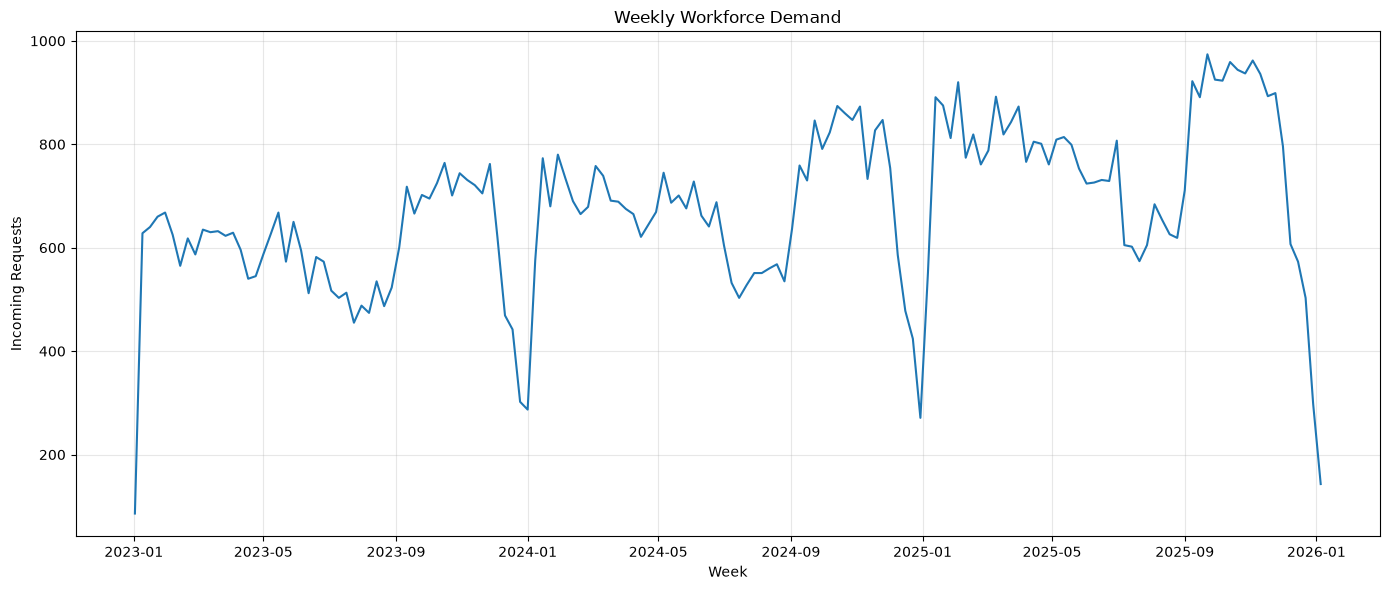

In [14]:
# Ploting weekly demand

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    weekly_total["date"],
    weekly_total["incoming_requests"],
)

ax.set_title("Weekly Workforce Demand")
ax.set_xlabel("Week")
ax.set_ylabel("Incoming Requests")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

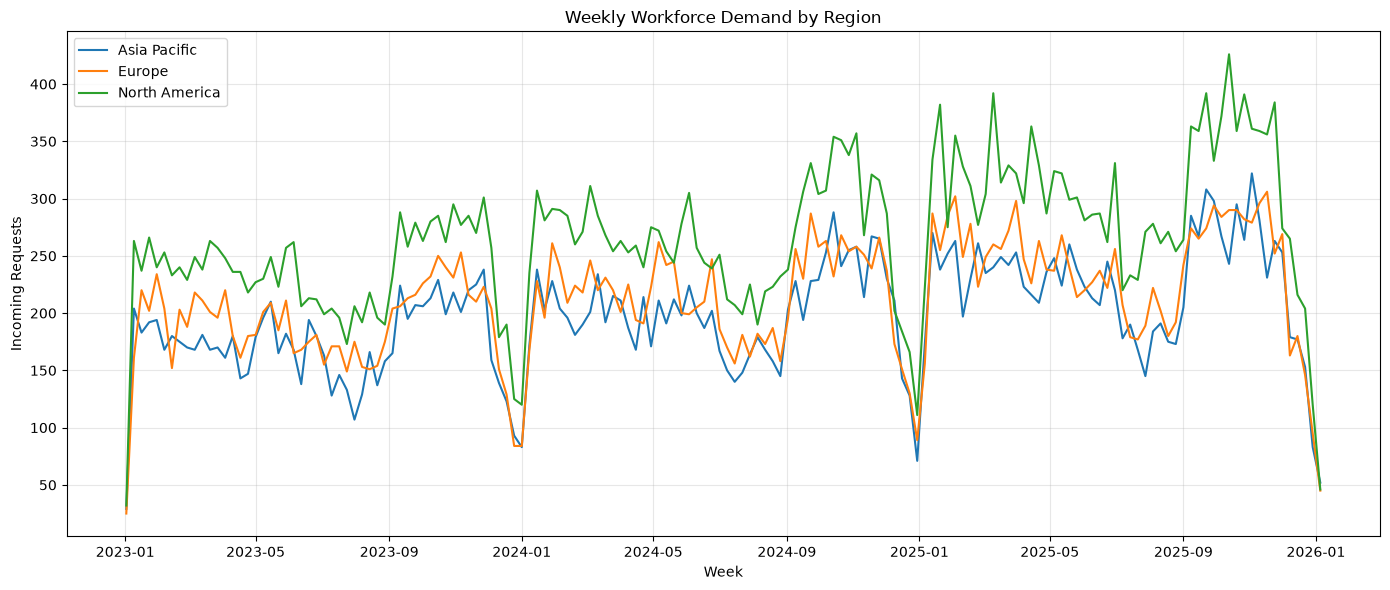

In [15]:
# Demand by region

weekly_region = (
    daily_region
    .set_index("date")
    .groupby("region")["incoming_requests"]
    .resample("W-MON")
    .sum()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(14, 6))

for region, region_data in weekly_region.groupby("region"):
    ax.plot(
        region_data["date"],
        region_data["incoming_requests"],
        label=region,
    )

ax.set_title("Weekly Workforce Demand by Region")
ax.set_xlabel("Week")
ax.set_ylabel("Incoming Requests")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

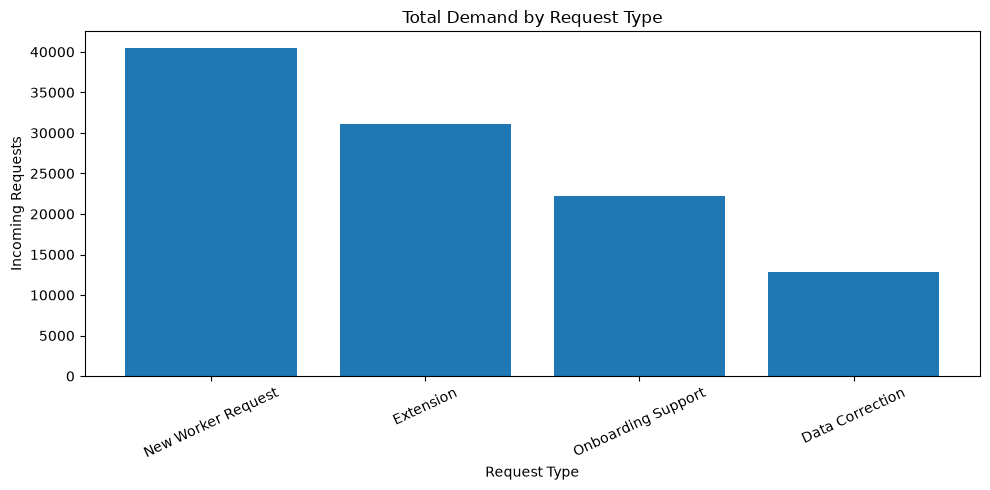

In [17]:
# Demand by request type
request_type_summary = (
    df.groupby("request_type", as_index=False)
    .agg(
        total_requests=("incoming_requests", "sum"),
        average_daily_requests=("incoming_requests", "mean"),
    )
    .sort_values("total_requests", ascending=False)
)

request_type_summary

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    request_type_summary["request_type"],
    request_type_summary["total_requests"],
)

ax.set_title("Total Demand by Request Type")
ax.set_xlabel("Request Type")
ax.set_ylabel("Incoming Requests")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

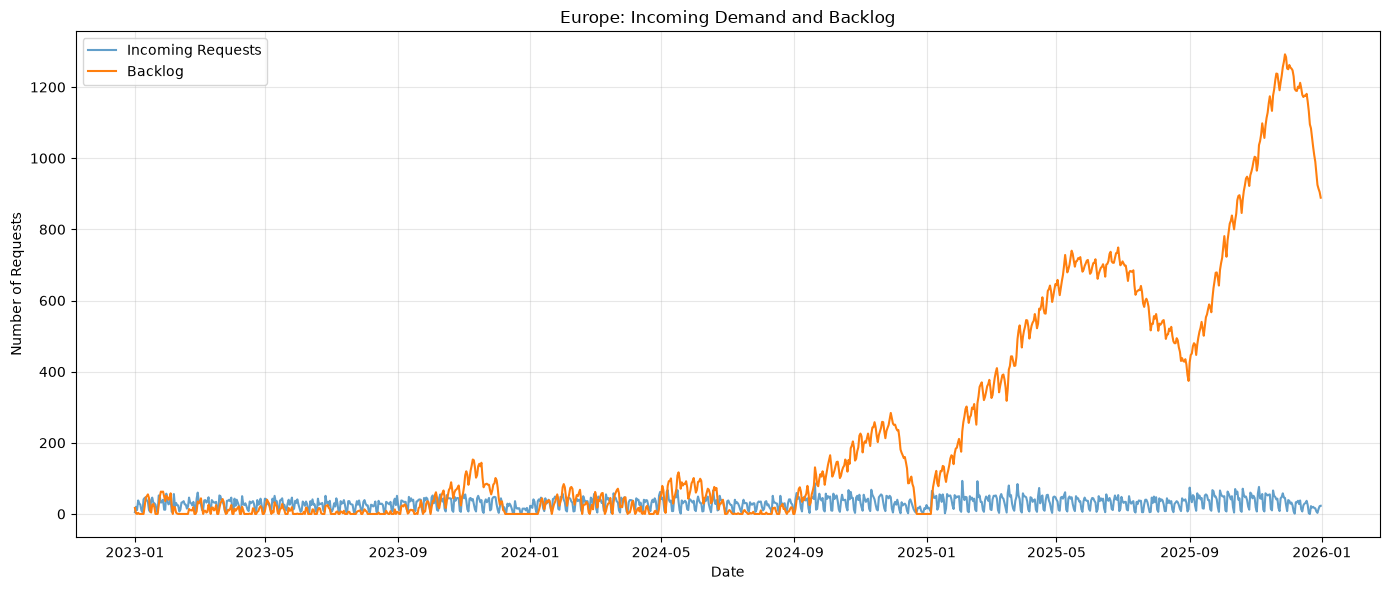

In [18]:
# Backlog versus incoming demand
europe_data = daily_region[
    daily_region["region"] == "Europe"
].sort_values("date")

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    europe_data["date"],
    europe_data["incoming_requests"],
    label="Incoming Requests",
    alpha=0.7,
)

ax.plot(
    europe_data["date"],
    europe_data["daily_backlog"],
    label="Backlog",
)

ax.set_title("Europe: Incoming Demand and Backlog")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Requests")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# aggregated dataset
PROCESSED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "daily_regional_demand.csv"
)

daily_region.to_csv(PROCESSED_PATH, index=False)

print(f"Saved processed dataset to: {PROCESSED_PATH}")
print(f"Rows saved: {len(daily_region):,}")

Saved processed dataset to: /home/vaibhav/Desktop/MSD/workforceDemandForecasting/data/processed/daily_regional_demand.csv
Rows saved: 3,288


In [20]:
# Testing the pipeline
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

sys.path.append(str(PROJECT_ROOT))

from src.features import build_feature_set

In [21]:
feature_df = build_feature_set(daily_region)

feature_df.head()

,date,region,incoming_requests,completed_requests,daily_backlog,available_staff,staff_absence_rate,is_weekend,is_month_end,is_holiday_period,...,month_sin,month_cos,incoming_requests_lag_1,incoming_requests_lag_2,incoming_requests_lag_7,incoming_requests_lag_14,incoming_requests_lag_30,rolling_mean_7,rolling_mean_30,rolling_std_7
0,2023-01-01,Asia Pacific,6,24,23,8,0.0419,1,0,1,...,0.5,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023-01-02,Asia Pacific,23,35,11,8,0.0307,0,0,1,...,0.5,0.866025,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2023-01-03,Asia Pacific,19,30,0,8,0.0214,0,0,1,...,0.5,0.866025,23.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN
9,2023-01-04,Asia Pacific,44,34,9,7,0.0871,0,0,0,...,0.5,0.866025,19.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
12,2023-01-05,Asia Pacific,38,28,18,8,0.0543,0,0,0,...,0.5,0.866025,44.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
feature_df.columns


Index(['date', 'region', 'incoming_requests', 'completed_requests',
       'daily_backlog', 'available_staff', 'staff_absence_rate', 'is_weekend',
       'is_month_end', 'is_holiday_period', 'demand_spike', 'day_of_week',
       'week_of_year', 'month', 'quarter', 'year', 'time_index', 'day_sin',
       'day_cos', 'month_sin', 'month_cos', 'incoming_requests_lag_1',
       'incoming_requests_lag_2', 'incoming_requests_lag_7',
       'incoming_requests_lag_14', 'incoming_requests_lag_30',
       'rolling_mean_7', 'rolling_mean_30', 'rolling_std_7'],
      dtype='str')

In [ ]:
# Missing values check
feature_df.isna().sum().sort_values(ascending=False)

incoming_requests_lag_30    90
rolling_mean_30             90
incoming_requests_lag_14    42
incoming_requests_lag_7     21
rolling_std_7               21
rolling_mean_7              21
incoming_requests_lag_2      6
incoming_requests_lag_1      3
date                         0
region                       0
incoming_requests            0
completed_requests           0
daily_backlog                0
week_of_year                 0
day_of_week                  0
demand_spike                 0
is_holiday_period            0
is_month_end                 0
is_weekend                   0
staff_absence_rate           0
available_staff              0
month_cos                    0
month_sin                    0
day_cos                      0
day_sin                      0
time_index                   0
year                         0
quarter                      0
month                        0
dtype: int64

In [24]:
feature_df = feature_df.dropna()

feature_df.to_csv(
    PROJECT_ROOT
    / "data"
    / "processed"
    / "feature_dataset.csv",
    index=False,
)

print(feature_df.shape)
feature_df.head()

(3198, 29)


,date,region,incoming_requests,completed_requests,daily_backlog,available_staff,staff_absence_rate,is_weekend,is_month_end,is_holiday_period,...,month_sin,month_cos,incoming_requests_lag_1,incoming_requests_lag_2,incoming_requests_lag_7,incoming_requests_lag_14,incoming_requests_lag_30,rolling_mean_7,rolling_mean_30,rolling_std_7
90,2023-01-31,Asia Pacific,43,24,25,8,0.0583,0,1,0,...,0.500000,0.866025,42.0,7.0,33.0,33.0,6.0,27.714286,26.733333,14.488090
93,2023-02-01,Asia Pacific,34,28,32,7,0.0763,0,0,0,...,0.866025,0.500000,43.0,42.0,33.0,39.0,23.0,29.142857,27.966667,15.550226
96,2023-02-02,Asia Pacific,34,30,36,7,0.0728,0,0,0,...,0.866025,0.500000,34.0,43.0,41.0,34.0,19.0,29.285714,28.333333,15.596092
99,2023-02-03,Asia Pacific,26,29,34,7,0.1086,0,0,0,...,0.866025,0.500000,34.0,34.0,30.0,27.0,44.0,28.285714,28.833333,14.929995
102,2023-02-04,Asia Pacific,11,22,24,7,0.1299,1,0,0,...,0.866025,0.500000,26.0,34.0,8.0,6.0,38.0,27.714286,28.233333,14.929995
